# Do mice use the visual stimulus to find the target?

The cbm-vision counterpart of `odor_search_strategy.ipynb`: same task, same analysis, with a visual cue in place of the odor.

**Task.** Each trial hides one target cell in a 3 x 9 grid. On `flip_state` 0 the target is in the four rows at the low-y end of the arena and a stimulus is shown on the monitor at that end; on `flip_state` 1 both are at the high-y end; on `flip_state` 2 no stimulus is shown and the target can be anywhere. The mouse finds the target by entering its cell, then drinks at a port in the middle row, waits out the ITI, and the next trial starts.

**How the cue differs from the odor.** The odor goes off when the target is found. The stimulus does not: it stays on through the reward and the ITI and changes only when the next trial starts (checked against the video-detected stimulus state in `vision_events.csv`). So when two consecutive trials share a `flip_state` the mouse sees no onset, and when they differ the stimulus at one end goes off as the other comes on. The two monitors are also on opposite long walls (flip 0: high-x side, flip 1: low-x side), so the cue is offset sideways as well as lengthwise; only the long axis is analysed here.

**What a mouse that had learned the task would do.** Go to the stimulus end, and stay there until it finds the target. That gives two separable behaviors to look for:

1. **Direction** - which end does the mouse head for? (flip 0 vs flip 1)
2. **Persistence** - once at the correct end, does it stay? (stimulus vs no-stimulus)

**Why the comparisons are built the way they are.** A search ends the moment the target is found, so on a flip-0 trial every path ends at the low end no matter what the mouse was doing. Occupancy, mean position and time-at-stimulus-end therefore differ between flip 0 and flip 1 even for a mouse wandering at random, and are not used here. Instead:

- *Direction* uses only trials that begin in the neutral middle row and asks which end zone is entered first. A trial cannot end before the mouse has entered the target's zone, so this is not affected by where the target is.
- *Persistence and search cost* compare each stimulus trial against **no-stimulus trials with the target in the same cell and the mouse starting in the same zone**. Those trials pose an identical search problem; the only thing that differs is the stimulus.

Zones: `low` = y < 890 px (flip-0 target rows), `high` = y >= 1068 px (flip-1 target rows), `mid` = the row between them, which holds both water ports. All sessions are of one type (`v`).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats as sps

from src import config as cfg
from src.trials import load_trials          # run `python -m src.trials vision` to rebuild output/trials_vision.csv
from src.stats import stratified_diff, per_mouse, summarize, logistic_fit

pd.set_option('display.width', 200, 'display.precision', 3)

SESSION_TYPES = ['v']
TYPE_LABEL = {'v': 'Vision'}
FLIP_COLOR = {0: '#2a78d6', 1: '#eb6834', 2: '#8a8985'}
FLIP_LABEL = {0: 'flip 0 (stimulus low)', 1: 'flip 1 (stimulus high)', 2: 'flip 2 (no stimulus)'}
INK, MUTED, GRID = '#0b0b0b', '#52514e', '#e4e3df'
plt.rcParams.update({
    'figure.facecolor': '#fcfcfb', 'axes.facecolor': '#fcfcfb', 'savefig.facecolor': '#fcfcfb',
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.edgecolor': MUTED,
    'axes.labelcolor': MUTED, 'xtick.color': MUTED, 'ytick.color': MUTED, 'text.color': INK,
    'axes.titlesize': 10, 'axes.titleweight': 'bold', 'axes.titlelocation': 'left',
    'axes.labelsize': 9, 'xtick.labelsize': 8, 'ytick.labelsize': 8, 'legend.fontsize': 8,
    'legend.frameon': False, 'figure.dpi': 110,
})

t = load_trials('vision')

## 1. Data

One row per searched trial. A search runs from the first frame of a trial (ITI over, stimulus switched to this trial's state) to the frame `target_cell` goes NaN (target consumed). Trial 0 (free reward) and trials whose target was never found are dropped. On every remaining trial the tracked nose is inside the target cell on the final frame, which confirms the grid geometry.

Sessions are read from `events/` where they exist and `events_temp/` otherwise (9003, 9007 and most of 9006 are only in `events_temp/`); the behavior columns used here are identical in the two. Each mouse contributes its first ten sessions: v0 to v9 for most. Mouse 9000 ran only six. Mouse 9009 has no v6, so its ten run to v10. Mouse 9007 ran session numbers 0 and 2 twice (`v0b`, `v2b`); the repeats count as sessions, so its ten run to v7.

In [2]:
print(f"{len(t)} searched trials, {t.groupby(['mouse', 'session']).ngroups} sessions, {t.mouse.nunique()} mice")
print(f"nose inside target cell at encounter: {(t.found_err_px == 0).mean():.1%}")
overview = t.groupby('session_type').agg(
    mice=('mouse', 'nunique'), sessions=('session', lambda s: t.loc[s.index].groupby(['mouse', 'session']).ngroups),
    trials=('trial', 'size'), median_search_s=('search_s', 'median'), median_path_px=('path_px', 'median'))
overview.join(pd.crosstab(t.session_type, t.flip).add_prefix('n_flip')).loc[SESSION_TYPES]

12129 searched trials, 86 sessions, 9 mice
nose inside target cell at encounter: 100.0%


,mice,sessions,trials,median_search_s,median_path_px,n_flip0,n_flip1,n_flip2
session_type,,,,,,,,
v,9,86,12129,6.041,3258.591,4048,4059,4022


## 2. Behavioral idiosyncrasies

Three things to pin down before reading anything into flip-state differences.

**Is the mouse's position at trial start independent of the trial type?** It has to be - the mouse has no information yet (the stimulus on screen during the ITI is the previous trial's). This is the negative control for everything below.

**Side bias.** Does the mouse favor one end regardless of trial type?

**Return to the previous target.** By the time the ITI ends, has the mouse drifted back toward where it last found a target?

In [3]:
start = pd.crosstab(t.flip, t.start_zone, normalize='index')[['low', 'mid', 'high']]
chi2, p, *_ = sps.chi2_contingency(pd.crosstab(t.flip[t.cue], t.start_zone[t.cue]))
print(f"Zone at trial start, flip 0 vs flip 1: chi2 = {chi2:.2f}, p = {p:.2f}")
start.rename(index=FLIP_LABEL)

Zone at trial start, flip 0 vs flip 1: chi2 = 3.14, p = 0.21


start_zone,low,mid,high
flip,,,
flip 0 (stimulus low),0.472,0.134,0.394
flip 1 (stimulus high),0.464,0.147,0.388
flip 2 (no stimulus),0.468,0.130,0.402


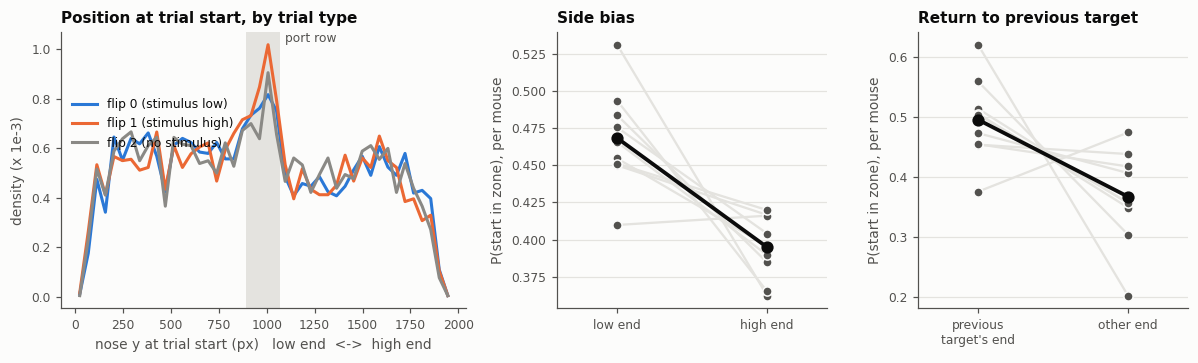

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(11, 3.4), gridspec_kw={'width_ratios': [1.5, 1, 1]})

ax = axes[0]
bins = np.linspace(0, cfg.FRAME_H, 45)
for flip in (0, 1, 2):
    density, _ = np.histogram(t.start_y[t.flip == flip], bins=bins, density=True)
    ax.plot((bins[:-1] + bins[1:]) / 2, density * 1000, color=FLIP_COLOR[flip], lw=2, label=FLIP_LABEL[flip])
ax.axvspan(cfg.LOW_MAX_Y, cfg.HIGH_MIN_Y, color=GRID, lw=0)
ax.text(cfg.HIGH_MIN_Y + 25, ax.get_ylim()[1], 'port row', ha='left', va='top', fontsize=8, color=MUTED)
ax.set(xlabel='nose y at trial start (px)   low end  <->  high end', ylabel='density (x 1e-3)',
       title='Position at trial start, by trial type')
ax.legend(loc='upper left', bbox_to_anchor=(0.0, 0.8))

def paired_dots(ax, a, b, labels, title, ylabel):
    for m in a.index:
        ax.plot([0, 1], [a[m], b[m]], color=GRID, lw=1.5, zorder=1)
    ax.scatter(np.zeros(len(a)), a, s=36, color=MUTED, zorder=2, edgecolor='#fcfcfb', lw=1)
    ax.scatter(np.ones(len(b)), b, s=36, color=MUTED, zorder=2, edgecolor='#fcfcfb', lw=1)
    ax.plot([0, 1], [a.mean(), b.mean()], color=INK, lw=2.5, marker='o', ms=7, zorder=3)
    ax.set(xticks=[0, 1], xticklabels=labels, xlim=(-0.4, 1.4), title=title, ylabel=ylabel)
    ax.yaxis.grid(True, color=GRID); ax.set_axisbelow(True)

by_mouse = t.groupby('mouse')
paired_dots(axes[1], by_mouse.start_zone.apply(lambda z: (z == 'low').mean()),
            by_mouse.start_zone.apply(lambda z: (z == 'high').mean()),
            ['low end', 'high end'], 'Side bias', 'P(start in zone), per mouse')
prev = t[t.prev_target_zone.isin(['low', 'high'])]
prev_by_mouse = prev.groupby('mouse')[['start_zone', 'prev_target_zone']]
paired_dots(axes[2], prev_by_mouse.apply(lambda d: (d.start_zone == d.prev_target_zone).mean()),
            prev_by_mouse.apply(lambda d: ((d.start_zone != d.prev_target_zone) & (d.start_zone != 'mid')).mean()),
            ["previous\ntarget's end", 'other end'], 'Return to previous target', 'P(start in zone), per mouse')
plt.tight_layout(); plt.show()

The control holds: position at trial start is the same for flip 0 and flip 1. Mice prefer the low end (47% of trials start there against 40% at the high end) and tend to be back at the previous target's end when the next trial starts (50% against 37% at the other end). Both are handled below by never comparing trials across different start zones, and by stratifying the direction analysis on the previous target's end.

## 3. Direction: which end does the mouse go to first?

Trials that start in the neutral middle row only. `P(low end first)` should be near 1 on flip 0 and near 0 on flip 1 for a mouse following the stimulus; flip 2 shows that mouse's side bias.

**Discrimination** = P(low first | flip 0) - P(low first | flip 1), computed within mouse x previous-target-end strata so that a return-to-previous-target habit cannot produce it. 0 = stimulus side ignored, 1 = perfect.

In [5]:
mid = t[(t.start_zone == 'mid') & (t.first_entry != 'none')].copy()
mid['low_first'] = (mid.first_entry == 'low').astype(float)
mid['is_flip0'] = mid.flip == 0

rows = {}
for st in SESSION_TYPES:
    d = mid[mid.session_type == st]
    p_low = d.groupby('flip').low_first.mean()
    rows[st] = {'P(low first) flip 0': p_low[0], 'flip 2': p_low[2], 'flip 1': p_low[1],
                **summarize(d[d.cue], 'low_first', 'is_flip0', ['prev_target_zone'])}
direction = pd.DataFrame(rows).T.rename(columns={'effect': 'discrimination'})
direction

,P(low first) flip 0,flip 2,flip 1,discrimination,p_perm,mouse_mean,ci_lo,ci_hi,mice_same_sign,n_trials
v,0.503,0.53,0.513,-0.001,0.967,-0.007,-0.062,0.048,5/9,1139


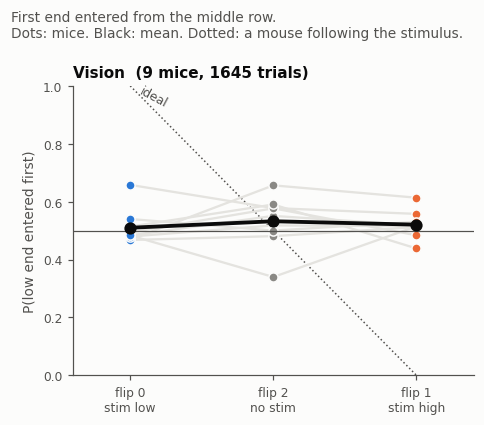

In [6]:
fig, axes = plt.subplots(1, len(SESSION_TYPES), figsize=(3.6 * len(SESSION_TYPES) + 0.8, 3.9), sharey=True, squeeze=False)
axes = axes[0]
order = [0, 2, 1]
for ax, st in zip(axes, SESSION_TYPES):
    d = mid[mid.session_type == st]
    pm = d.groupby(['mouse', 'flip']).low_first.mean().unstack()[order]
    for m in pm.index:
        ax.plot(range(3), pm.loc[m], color=GRID, lw=1.5, zorder=1)
    for i, flip in enumerate(order):
        ax.scatter(np.full(len(pm), i), pm[flip], s=36, color=FLIP_COLOR[flip], edgecolor='#fcfcfb', lw=1, zorder=2)
    ax.plot(range(3), pm.mean(), color=INK, lw=2.5, marker='o', ms=7, zorder=3)
    ax.plot(range(3), [1, 0.5, 0], color=MUTED, lw=1, ls=':', zorder=0)
    ax.axhline(0.5, color=MUTED, lw=0.8)
    ax.set(xticks=range(3), xticklabels=['flip 0\nstim low', 'flip 2\nno stim', 'flip 1\nstim high'], xlim=(-0.4, 2.4),
           ylim=(0, 1), title=f"{TYPE_LABEL[st]}  ({len(pm)} mice, {len(d)} trials)")
axes[0].set_ylabel('P(low end entered first)')
axes[0].text(0.05, 0.93, 'ideal', color=MUTED, fontsize=8, rotation=-28)
fig.suptitle('First end entered from the middle row.\nDots: mice. Black: mean. Dotted: a mouse following the stimulus.',
             x=0.01, ha='left', fontsize=9, color=MUTED)
plt.tight_layout(); plt.show()

The same question as a regression, so the stimulus's pull can be read next to the two idiosyncrasies on a common scale (log-odds of entering the low end first; mouse identity ignored, coefficients are descriptive):

In [7]:
def choice_model(d):
    X = np.c_[(d.flip == 0).astype(float) - (d.flip == 1), (d.prev_target_zone == 'low').astype(float) - (d.prev_target_zone == 'high')]
    intercept, coef = logistic_fit(X, d.low_first)
    return pd.Series({'stimulus side': coef[0], "previous target's side": coef[1], 'low-end bias': intercept})

pd.DataFrame({st: choice_model(mid[mid.session_type == st]) for st in SESSION_TYPES}).T

,stimulus side,previous target's side,low-end bias
v,-0.019,0.082,0.06


### Does a fresh onset help?

Because the stimulus persists through the ITI, a trial that follows a no-stimulus trial is the only kind where the cue appears on a blank screen, and it is also the kind most like an odor trial. After a stimulus trial the screen either does not change (same `flip_state`) or switches ends, and in both of those cases the cue's side is tied to the previous target's side, so they cannot be separated from the return-to-previous-target habit. Discrimination restricted to trials that follow a no-stimulus trial:

In [8]:
fresh = mid[mid.cue & (mid.prev_flip == 2)]
pd.DataFrame({st: summarize(fresh[fresh.session_type == st], 'low_first', 'is_flip0', ['prev_target_zone'])
              for st in SESSION_TYPES}).T.rename(columns={'effect': 'discrimination'})

,discrimination,p_perm,mouse_mean,ci_lo,ci_hi,mice_same_sign,n_trials
v,0.038,0.502,-0.018,-0.19,0.153,5/9,355


## 4. Persistence and search cost: stimulus vs matched no-stimulus trials

Each search is split at the first frame the mouse is in the target's end zone:

- **approach** - everything before that (zero if the mouse started there). `wrong_end_first`: it visited the other end before the correct one.
- **local search** - everything after. `left_after_reach`: having been at the correct end, it went all the way to the other end before finding the target.

Effects are stimulus minus no-stimulus, within strata of mouse x target cell x start zone. Matching on the exact cell matters: flip 0 and flip 1 draw the center cell of their second row twice as often as any other, and those cells are easier to hit. Path effects are log2 ratios (-0.15 is about 10% shorter). Searches longer than `MAX_SEARCH_S` are dropped as disengaged.

In [9]:
MATCH = ['target_cell', 'start_zone']
METRICS = {   # name: (column, which trials)
    'whole search path (log2)':      ('log2_path_px',       ['same end', 'opposite end', 'from middle']),
    'approach path (log2)':          ('log2_reach_path_px', ['opposite end', 'from middle']),
    'P(wrong end first)':            ('wrong_end_first',    ['from middle']),
    'local search path (log2)':      ('log2_local_path_px', ['same end', 'opposite end', 'from middle']),
    'P(left correct end)':           ('left_after_reach',   ['same end', 'opposite end', 'from middle']),
}
cost = t[(t.geometry != 'target in middle') & (t.search_s <= cfg.MAX_SEARCH_S)]

rows = {}
for st in SESSION_TYPES:
    for name, (col, geoms) in METRICS.items():
        d = cost[(cost.session_type == st) & cost.geometry.isin(geoms)]
        base = d.loc[~d.cue, col].mean()
        rows[(st, name)] = {'no-stimulus mean': base, **summarize(d, col, 'cue', MATCH)}
matched = pd.DataFrame(rows).T
matched

no-stimulus mean effect p_perm mouse_mean  ci_lo  ci_hi mice_same_sign n_trials
v whole search path (log2)           11.455 -0.012  0.754     -0.008 -0.096   0.08            3/9    11532
  approach path (log2)               10.331  0.036  0.334       0.03 -0.035  0.094            5/9     6532
  P(wrong end first)                  0.488  0.022  0.459       0.02 -0.065  0.105            5/9     1586
  local search path (log2)           10.712 -0.029  0.519     -0.025 -0.126  0.077            5/9    11532
  P(left correct end)                 0.414  0.003  0.726      0.005  -0.02   0.03            6/9    11532

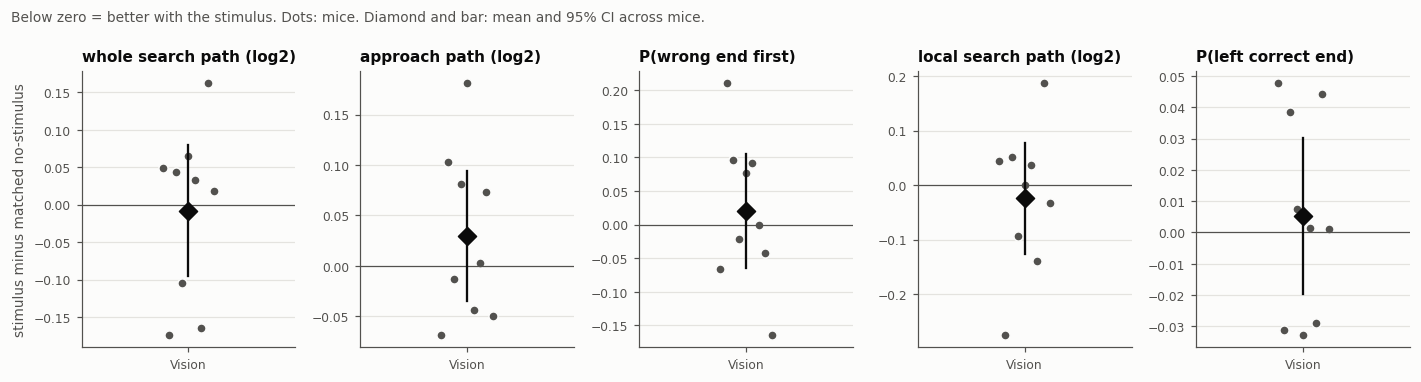

In [10]:
fig, axes = plt.subplots(1, len(METRICS), figsize=(13, 3.5))
for ax, (name, (col, geoms)) in zip(axes, METRICS.items()):
    for i, st in enumerate(SESSION_TYPES):
        d = cost[(cost.session_type == st) & cost.geometry.isin(geoms)]
        pm = per_mouse(d, col, 'cue', MATCH).dropna()
        jitter = np.linspace(-0.12, 0.12, len(pm))
        ax.scatter(i + jitter, pm, s=36, color=MUTED, edgecolor='#fcfcfb', lw=1, zorder=2)
        r = matched.loc[(st, name)]
        ax.plot([i, i], [r.ci_lo, r.ci_hi], color=INK, lw=1.5, zorder=3)
        ax.scatter([i], [r.mouse_mean], s=70, color=INK, marker='D', zorder=4)
    ax.axhline(0, color=MUTED, lw=0.8)
    ax.set(xticks=range(len(SESSION_TYPES)), xticklabels=[TYPE_LABEL[s] for s in SESSION_TYPES],
           xlim=(-0.5, len(SESSION_TYPES) - 0.5), title=name)
    ax.yaxis.grid(True, color=GRID); ax.set_axisbelow(True)
axes[0].set_ylabel('stimulus minus matched no-stimulus')
fig.suptitle('Below zero = better with the stimulus. Dots: mice. Diamond and bar: mean and 95% CI across mice.',
             x=0.01, ha='left', fontsize=9, color=MUTED)
plt.tight_layout(); plt.show()

### Do the two stimulus conditions differ from each other?

The same matched comparison, separately for flip 0 (against no-stimulus trials with a low-end target) and flip 1 (against no-stimulus trials with a high-end target).

In [11]:
rows = {}
for st in SESSION_TYPES:
    for flip, zone in ((0, 'low'), (1, 'high')):
        d = cost[(cost.session_type == st) & (cost.target_zone == zone)]
        rows[(st, FLIP_LABEL[flip])] = {
            'P(left correct end), stimulus': d.loc[d.cue, 'left_after_reach'].mean(),
            'no stimulus': d.loc[~d.cue, 'left_after_reach'].mean(),
            'matched diff': stratified_diff(d, 'left_after_reach', 'cue', ['mouse'] + MATCH),
            'whole path (log2), matched diff': stratified_diff(d, 'log2_path_px', 'cue', ['mouse'] + MATCH),
            'n stimulus': int(d.cue.sum()), 'n no stimulus': int((~d.cue).sum())}
pd.DataFrame(rows).T

P(left correct end), stimulus  no stimulus  matched diff  whole path (log2), matched diff  n stimulus  n no stimulus
v flip 0 (stimulus low)                           0.414        0.423         0.001                           -0.052      4039.0         1722.0
  flip 1 (stimulus high)                          0.398        0.405         0.006                            0.028      4047.0         1724.0

## 5. Across sessions

Both measures by how many sessions the mouse has had (its 1st to 10th), pooling mice. If mice were learning, discrimination should climb toward 1 and the persistence effect should grow more negative.

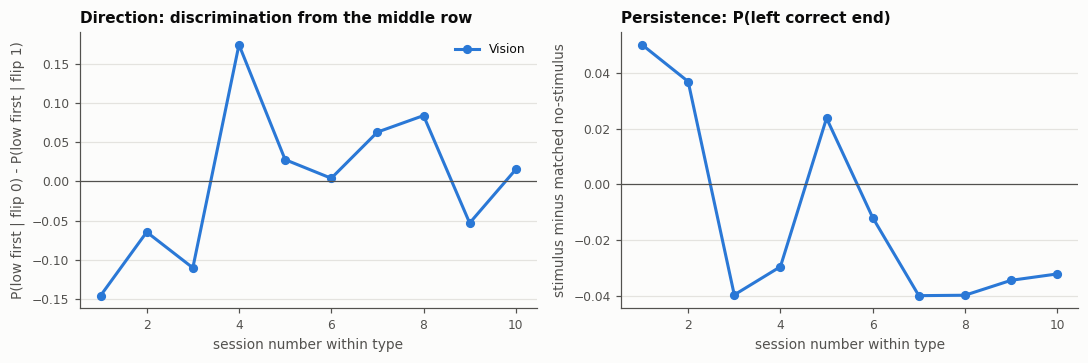

In [12]:
def by_session(d, y, label, keys, min_trials):
    out = d.groupby(['session_type', 'session_num'])[[y, label] + keys].apply(
        lambda g: pd.Series({'effect': stratified_diff(g, y, label, keys), 'n': len(g)}))
    return out[out.n >= min_trials]

disc = by_session(mid[mid.cue], 'low_first', 'is_flip0', ['mouse'], 30)
pers = by_session(cost, 'left_after_reach', 'cue', ['mouse', 'target_zone', 'start_zone'], 150)

TYPE_COLOR = {'v': '#2a78d6'}
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
for ax, data, title, ylabel in ((axes[0], disc, 'Direction: discrimination from the middle row', 'P(low first | flip 0) - P(low first | flip 1)'),
                                (axes[1], pers, 'Persistence: P(left correct end)', 'stimulus minus matched no-stimulus')):
    for st in SESSION_TYPES:
        s = data.loc[st].effect
        ax.plot(s.index, s.values, color=TYPE_COLOR[st], lw=2, marker='o', ms=5, label=TYPE_LABEL[st])
    ax.axhline(0, color=MUTED, lw=0.8)
    ax.set(title=title, ylabel=ylabel, xlabel='session number within type')
    ax.yaxis.grid(True, color=GRID); ax.set_axisbelow(True)
axes[0].legend()
plt.tight_layout(); plt.show()

## Summary

**The visual stimulus has no detectable effect on how mice search.** Every measure of direction, persistence and search cost is indistinguishable from the no-stimulus condition, in 12,129 trials from 9 mice.

**Direction (flip 0 vs flip 1).**
- From the middle row, mice enter the low end first on 50% of flip-0 trials, 51% of flip-1 trials and 53% of no-stimulus trials. Discrimination is 0.00 (95% CI across mice -0.06 to 0.05; 1,139 stimulus trials, p = 0.97).
- In the regression the stimulus side has a weight of -0.02, smaller than the previous-target habit (0.08) or the low-end bias (0.06).
- Restricting to trials where the stimulus appears on a blank screen (after a no-stimulus trial) does not change this: 0.04, CI -0.19 to 0.15, 355 trials.

**Stimulus vs matched no-stimulus (persistence and cost).**
- None of the five measures differs from zero (all p >= 0.33) and none has a consistent sign across mice (3/9 to 6/9).
- Whole search path: log2 ratio -0.01 (CI -0.10 to 0.08), i.e. about 1% shorter, with anything beyond about 6% shorter excluded.
- P(left correct end): +0.3 percentage points on a 41% no-stimulus baseline (CI -2.0 to +3.0).
- Flip 0 and flip 1 look the same; neither end's stimulus is used.

**Idiosyncrasies.** Position at trial start is independent of trial type (p = 0.21). The low-end preference and the return to the previous target's end are both present and cannot produce a stimulus effect, because comparisons are made within start zone and within previous-target end.

**No learning across sessions.** Neither measure trends over the ten sessions; both wander around zero.

**Reading the results.**
- This says the mice do not *use* the stimulus, not that they cannot see it. Whether the monitor is in view from where a trial starts is not considered here; `vision_events.csv` has a per-frame field-of-view estimate for the sessions already in `events/` and would be the way to test that.
- The stimulus stays on through the ITI, so on about a third of stimulus trials nothing changes at trial start. The fresh-onset check above suggests that is not what hides an effect, but with 355 trials it would only detect a large one.
- No test here reaches p < 0.05, so multiple-comparison correction does not change anything.
- Excluded: sessions beyond each mouse's ten, trial 0 of each session, trials with no target found, and (section 4 only) searches over 120 s (0.2% of trials) and no-stimulus trials with the target in the middle row.